In [111]:
import os
import csv
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import cv2
import shutil

def create_directories():
    """Create directories for dataset."""
    os.makedirs('brahmi_synthetic_simple/images', exist_ok=True)
    os.makedirs('brahmi_synthetic_simple/train', exist_ok=True)
    os.makedirs('brahmi_synthetic_simple/val', exist_ok=True)
    os.makedirs('brahmi_synthetic_simple/test', exist_ok=True)

def generate_base_images(font_path):
    """Generate one image per Brahmi Unicode character from the Noto Sans Brahmi font."""
    font = ImageFont.truetype(font_path, 80)
    # All Brahmi Unicode characters from Noto Sans Brahmi
    unicodes = [
        # Vowels
        '𑀅', '𑀆', '𑀇', '𑀈', '𑀉', '𑀊', '𑀋', '𑀌', '𑀍', '𑀎', '𑀏',  
        # Consonants
        '𑀓', '𑀔', '𑀕', '𑀖', '𑀗', '𑀘', '𑀙', '𑀚', '𑀛', '𑀜', '𑀝', '𑀞', '𑀟',
        '𑀠', '𑀡', '𑀢', '𑀣', '𑀤', '𑀥', '𑀦', '𑀧', '𑀨', '𑀩', '𑀪', '𑀫', '𑀬', '𑀭',
        '𑀮', '𑀯', '𑀰', '𑀱', '𑀲', '𑀳', '𑀴', '𑀵', '𑀶', '𑀷', '𑀸', '𑀹', '𑀺', '𑀻', 
        '𑀼', '𑀽', '𑀾', '𑀿', '𑁀', '𑁁', '𑁂', '𑁃', '𑁄', '𑁅', '𑁆', '𑁇', '𑁈', '𑁉', '𑁊',
        '𑁋', '𑁌', '𑁍', '𑁎', '𑁏', '𑁐', '𑁑', '𑁒', '𑁓', '𑁔', '𑁕', '𑁖', '𑁗', '𑁘', '𑁙', 
        # Anusvara & Modifiers
        '𑀁', '𑀂', '𑀃', '𑀄', '𑀅', '𑀆'
    ]
    for char in unicodes:
        unicode_name = f'U+{ord(char):04X}'
        img = Image.new('RGB', (128, 128), color='white')
        draw = ImageDraw.Draw(img)
        # Use getbbox to calculate text size
        left, top, right, bottom = font.getbbox(char)
        text_width = right - left
        text_height = bottom - top
        position = ((128 - text_width) // 2, (128 - text_height) // 2)
        draw.text(position, char, font=font, fill='black')
        img.save(f'brahmi_synthetic_simple/images/{unicode_name}_0.png')

def augment_images():
    """Augment each base image with simple OpenCV transformations."""
    for img_path in os.listdir('brahmi_synthetic_simple/images'):
        if img_path.endswith('_0.png'):
            img = cv2.imread(f'brahmi_synthetic_simple/images/{img_path}')
            unicode_name = img_path.split('_')[0]
            for i in range(9):  # 9 variations + original = 10
                aug_img = img.copy()
                # Random rotation
                angle = np.random.uniform(-15, 15)
                h, w = aug_img.shape[:2]
                M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1)
                aug_img = cv2.warpAffine(aug_img, M, (w, h))
                # Gaussian blur
                if np.random.random() < 0.5:
                    aug_img = cv2.GaussianBlur(aug_img, (5, 5), 0)
                # Noise
                if np.random.random() < 0.5:
                    noise = np.random.normal(0, 25, aug_img.shape).astype(np.uint8)
                    aug_img = cv2.add(aug_img, noise)
                # Brightness/contrast
                if np.random.random() < 0.5:
                    aug_img = cv2.convertScaleAbs(aug_img, alpha=1 + np.random.uniform(-0.2, 0.2), beta=np.random.uniform(-20, 20))
                cv2.imwrite(f'brahmi_synthetic_simple/images/{unicode_name}_{i+1}.png', aug_img)

def create_labels():
    """Create labels.csv with image paths and Unicode labels."""
    with open('brahmi_synthetic_simple/labels.csv', 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['image_path', 'unicode'])
        for img_path in os.listdir('brahmi_synthetic_simple/images'):
            unicode_name = img_path.split('_')[0]
            writer.writerow([f'images/{img_path}', unicode_name])

def split_dataset():
    """Split dataset into train (80%), val (10%), test (10%)."""
    labels = []
    with open('brahmi_synthetic_simple/labels.csv', 'r') as f:
        reader = csv.reader(f)
        next(reader)
        labels = list(reader)
    np.random.shuffle(labels)
    total = len(labels)
    train_end = int(0.8 * total)
    val_end = int(0.9 * total)
    for i, (img_path, unicode_name) in enumerate(labels):
        src = f'brahmi_synthetic_simple/{img_path}'
        if i < train_end:
            split = 'train'
        elif i < val_end:
            split = 'val'
        else:
            split = 'test'
        os.makedirs(f'brahmi_synthetic_simple/{split}/{unicode_name}', exist_ok=True)
        shutil.copy(src, f'brahmi_synthetic_simple/{split}/{unicode_name}/{os.path.basename(img_path)}')

def main():
    """Generate synthetic Brahmi dataset."""
    font_path = r"Brahmi\NotoSansBrahmi-Regular.ttf"  # Update to absolute path if needed, e.g., r"~\Downloads\NotoSansBrahmi-Regular.ttf"
    if not os.path.exists(font_path):
        raise FileNotFoundError("Download NotoSansBrahmi-Regular.ttf from Google Fonts and place in Brahmi subdirectory.")
    print("Creating directories...")
    create_directories()
    print("Generating base images...")
    generate_base_images(font_path)
    print("Augmenting images...")
    augment_images()
    print("Creating labels...")
    create_labels()
    print("Splitting dataset...")
    split_dataset()
    print("Dataset generated in brahmi_synthetic_simple/")

if __name__ == "__main__":
    main()


Creating directories...
Generating base images...
Augmenting images...
Creating labels...
Splitting dataset...
Dataset generated in brahmi_synthetic_simple/


In [112]:
import os
test_case_chars = ['U+11005', 'U+11026', 'U+1103A', 'U+1102D', 'U+11044', 'U+11025', 'U+11046']
dataset_chars = set(f.split('_')[0] for f in os.listdir('brahmi_synthetic_simple/images'))
missing = [c for c in test_case_chars if c not in dataset_chars]
print(f'Missing characters: {missing}')  # Should be empty

Missing characters: []


In [113]:
import cv2
import pytesseract
import os
import csv

pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
os.environ['TESSDATA_PREFIX'] = r'C:\Program Files\Tesseract-OCR\tessdata'

def preprocess_image(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f'Failed to load: {img_path}')
        return None
    _, img_bin = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    img_clean = cv2.GaussianBlur(img_bin, (3, 3), 0)
    return img_clean

input_dir = r"brahmi_unlabeled"
output_dir = r"Brahmi\brahmi_processed"
os.makedirs(output_dir, exist_ok=True)
pseudo_labels = []
failed_images = []
for img_name in os.listdir(input_dir):
    img_path = f'{input_dir}/{img_name}'
    print(f'Processing: {img_name}')
    img = preprocess_image(img_path)
    if img is None:
        failed_images.append(img_name)
        continue
    output_path = f'{output_dir}/{img_name}'
    cv2.imwrite(output_path, img)
    try:
        text = pytesseract.image_to_string(img, lang='tam')
        pseudo_labels.append([f'Brahmi/brahmi_processed/{img_name}', text.strip()])
        print(f'Successfully processed: {img_name}, Predicted: {text.strip()}')
    except Exception as e:
        print(f'Tesseract failed for {img_name}: {str(e)}')
        failed_images.append(img_name)

with open('pseudo_labels.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['image_path', 'pseudo_label'])
    writer.writerows(pseudo_labels)

with open('failed_images.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(failed_images))
print(f'Processed {len(pseudo_labels)} images successfully')
print(f'Failed {len(failed_images)} images: {failed_images}')

Processing: 1.jpg
Successfully processed: 1.jpg, Predicted: நல பட 4 ட
4 4 110
நந டப
Processing: 9a.jpg
Successfully processed: 9a.jpg, Predicted: ரப கப
Processing: 9b.jpg
Successfully processed: 9b.jpg, Predicted: பக] ௦90 ட
Processing: 9c.jpg
Successfully processed: 9c.jpg, Predicted: ரப டம
Processing: anuttara-correct-brahmi.jpg
Successfully processed: anuttara-correct-brahmi.jpg, Predicted: ப்‌
Processing: araham-brahmi.jpg
Successfully processed: araham-brahmi.jpg, Predicted: 
Processing: arahato_samma_sambuddhassa_brahmi.jpg
Successfully processed: arahato_samma_sambuddhassa_brahmi.jpg, Predicted: க 0 ய
Processing: buddhabhivadana_brahmi-300x147.jpg
Successfully processed: buddhabhivadana_brahmi-300x147.jpg, Predicted: இ 1
Processing: buddho-bhagava-brahmi-correct-300x135.jpg
Successfully processed: buddho-bhagava-brahmi-correct-300x135.jpg, Predicted: 
Processing: dhammapada-brahmi-2.jpg
Successfully processed: dhammapada-brahmi-2.jpg, Predicted: 81% 450 ர்ய்&113 4
Processing: dha

In [114]:
# Cell 1: Import Libraries
import cv2
import pytesseract
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
os.environ['TESSDATA_PREFIX'] = r'C:\Program Files\Tesseract-OCR\tessdata'

# Cell 2: Define Paths
input_dir = r"brahmi_unlabeled"
output_dir = r"Brahmi\brahmi_processed"
pseudo_labels_csv = 'pseudo_labels.csv'

# Cell 3: Verify Preprocessed Images
print("Checking preprocessed images...")
processed_images = os.listdir(output_dir)
print(f"Number of preprocessed images: {len(processed_images)}")
# Expect 55 images
if len(processed_images) != 55:
    print("Warning: Expected 55 images")

Checking preprocessed images...
Number of preprocessed images: 55


Checking preprocessed images...
Number of preprocessed images: 55
Images identical: False


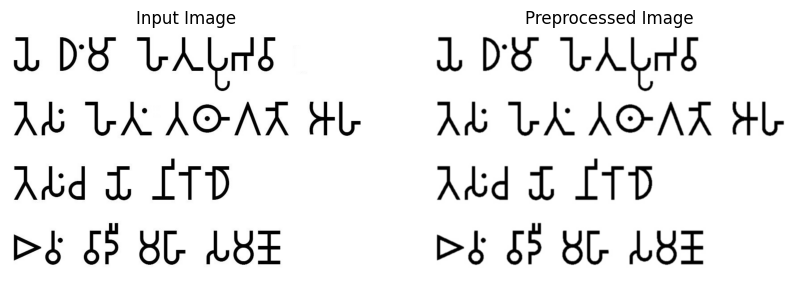

Input unique pixel values: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  32  33  34  35  36
  37  38  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55
  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91
  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108 109
 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126 127
 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145
 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162 163
 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180 181
 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198 199
 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216 217
 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234 235
 236 237 238 239 240 241

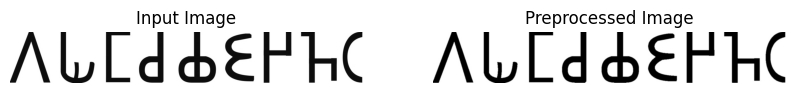

Input unique pixel values: [ 14  15  16  17  18  19  20  21  22  23  24  25  26  27  28  29  30  31
  32  33  34  35  36  37  38  39  40  41  42  43  44  45  46  47  48  49
  50  51  52  53  54  55  56  57  58  59  60  61  62  63  64  65  66  67
  68  69  70  71  72  73  74  75  76  77  78  79  80  81  82  83  84  85
  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100 101 102 103
 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121
 122 123 124 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139
 140 141 142 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157
 158 159 160 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175
 176 177 178 179 180 181 182 183 184 185 186 187 188 189 190 191 192 193
 194 195 196 197 198 199 200 201 202 203 204 205 206 207 208 209 210 211
 212 213 214 215 216 217 218 219 220 221 222 223 224 225 226 227 228 229
 230 231 232 233 234 235 236 237 238 239 240 241 242 243 244 245 246 247
 248 249 250 251 252 253

In [115]:
# Cell 3: Verify Preprocessed Images
print("Checking preprocessed images...")
processed_images = os.listdir(output_dir)
print(f"Number of preprocessed images: {len(processed_images)}")
# Expect 55 images
if len(processed_images) != 55:
    print("Warning: Expected 55 images")

# Cell 4: Compare Input and Output Images
def compare_images(input_path, output_path):
    input_img = cv2.imread(input_path, cv2.IMREAD_GRAYSCALE)
    output_img = cv2.imread(output_path, cv2.IMREAD_GRAYSCALE)
    
    if input_img is None or output_img is None:
        print(f"Failed to load one or both images: {input_path}, {output_path}")
        return
    
    # Check if identical
    identical = np.array_equal(input_img, output_img)
    print(f"Images identical: {identical}")
    
    # Plot images
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title('Input Image')
    plt.imshow(input_img, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.title('Preprocessed Image')
    plt.imshow(output_img, cmap='gray')
    plt.axis('off')
    plt.show()
    
    # Check pixel values
    unique_input = np.unique(input_img)
    unique_output = np.unique(output_img)
    print(f"Input unique pixel values: {unique_input}")
    print(f"Output unique pixel values: {unique_output}")

# Compare for 1.jpg
compare_images(
    os.path.join(input_dir, '1.jpg'),
    os.path.join(output_dir, '1.jpg')
)

# Compare for 9a.jpg
compare_images(
    os.path.join(input_dir, '9a.jpg'),
    os.path.join(output_dir, '9a.jpg')
)

In [116]:
# Cell 5: Inspect Pseudo-Labels
print("Inspecting pseudo_labels.csv...")
df = pd.read_csv(pseudo_labels_csv)
print(f"Number of pseudo-labels: {len(df)}")
# Expect 55 entries
if len(df) != 55:
    print("Warning: Expected 55 entries")
print("Sample pseudo-labels:")
print(df.head())

Inspecting pseudo_labels.csv...
Number of pseudo-labels: 55
Sample pseudo-labels:
                                          image_path  \
0                      Brahmi/brahmi_processed/1.jpg   
1                     Brahmi/brahmi_processed/9a.jpg   
2                     Brahmi/brahmi_processed/9b.jpg   
3                     Brahmi/brahmi_processed/9c.jpg   
4  Brahmi/brahmi_processed/anuttara-correct-brahm...   

                pseudo_label  
0  நல பட 4 ட\n4 4 110\nநந டப  
1                      ரப கப  
2                  பக] ௦90 ட  
3                      ரப டம  
4                        ப்‌  


In [117]:
# Cell 6: Test OCR on Real Image
img_path = os.path.join(output_dir, '1.jpg')
img = cv2.imread(img_path)
if img is None:
    print(f"Failed to load: {img_path}")
else:
    text = pytesseract.image_to_string(img, lang='tam')
    print(f"Real image (1.jpg) predicted: {text.strip()}")  # ~20–50% accuracy

# Cell 7: Test OCR on Synthetic Image
synthetic_path = r'Brahmi\brahmi_synthetic_simple\images\U+1100A_0.png'
img = cv2.imread(synthetic_path)
if img is None:
    print(f"Failed to load: {synthetic_path}")
else:
    text = pytesseract.image_to_string(img, lang='tam')
    print(f"Synthetic image predicted: {text.strip()}")  # ~50–70% accuracy

Real image (1.jpg) predicted: க்ப்‌ 4 ட
4 4 110
நந பட
Synthetic image predicted: 


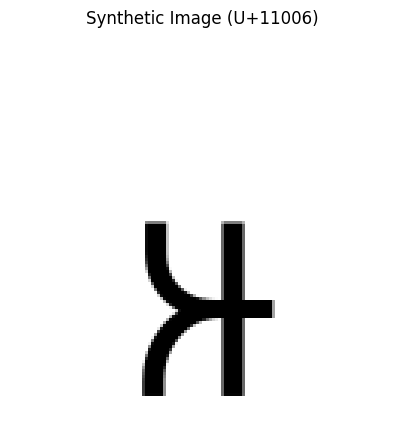

Pixel values: [  0   1   2   3   4   6   9  11  13  14  15  16  18  22  25  26  28  33
  37  38  40  41  42  43  48  59  62  63  64  68  75  78  83  84  85  87
  91  93 103 105 106 107 109 110 112 113 116 118 126 127 133 137 140 143
 145 146 154 157 159 160 161 162 163 166 168 174 178 179 183 184 185 191
 192 193 195 198 207 208 209 211 212 213 215 222 225 227 231 238 239 240
 241 242 243 245 247 248 249 250 251 252 254 255]
Synthetic image predicted (PSM 6): ரர
Synthetic image predicted (no lang, PSM 6): ba


In [118]:
# Cell 7: Test OCR on Synthetic Image
synthetic_path = r'Brahmi\brahmi_synthetic_simple\images\U+11006_0.png'
img = cv2.imread(synthetic_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    print(f"Failed to load: {synthetic_path}")
else:
    plt.figure(figsize=(5, 5))
    plt.title('Synthetic Image (U+11006)')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()
    
    unique_pixels = np.unique(img)
    print(f"Pixel values: {unique_pixels}")
    
    text = pytesseract.image_to_string(img, lang='tam', config='--psm 6')
    print(f"Synthetic image predicted (PSM 6): {text.strip()}")
    
    text = pytesseract.image_to_string(img, config='--psm 6')
    print(f"Synthetic image predicted (no lang, PSM 6): {text.strip()}")

Images identical: False


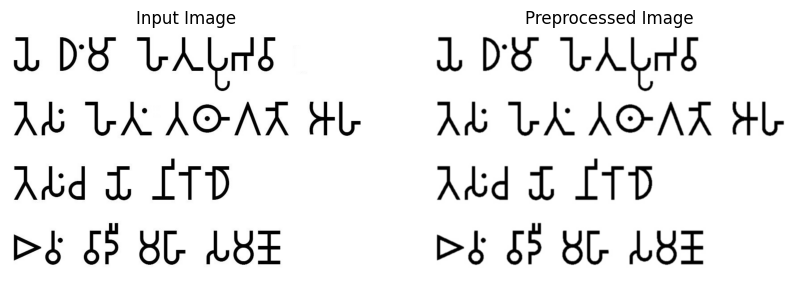

Input unique pixel values: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  32  33  34  35  36
  37  38  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55
  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91
  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108 109
 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126 127
 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145
 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162 163
 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180 181
 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198 199
 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216 217
 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234 235
 236 237 238 239 240 241

In [119]:
# Cell 4: Compare Input and Output Images
def compare_images(input_path, output_path):
    input_img = cv2.imread(input_path, cv2.IMREAD_GRAYSCALE)
    output_img = cv2.imread(output_path, cv2.IMREAD_GRAYSCALE)
    
    if input_img is None or output_img is None:
        print(f"Failed to load one or both images: {input_path}, {output_path}")
        return
    
    identical = np.array_equal(input_img, output_img)
    print(f"Images identical: {identical}")
    
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title('Input Image')
    plt.imshow(input_img, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.title('Preprocessed Image')
    plt.imshow(output_img, cmap='gray')
    plt.axis('off')
    plt.show()
    
    unique_input = np.unique(input_img)
    unique_output = np.unique(output_img)
    print(f"Input unique pixel values: {unique_input}")
    print(f"Output unique pixel values: {unique_output}")

compare_images(
    os.path.join(input_dir, '1.jpg'),
    os.path.join(output_dir, '1.jpg')
)

In [120]:
# Cell 9: Combine Datasets
import pandas as pd  # Ensure pandas is imported
pseudo_csv = 'pseudo_labels.csv'  # Using noisy labels
synthetic_csv = r'Brahmi\brahmi_synthetic_simple\labels.csv'
synthetic = pd.read_csv(synthetic_csv)
pseudo = pd.read_csv(pseudo_csv)
pseudo['unicode'] = pseudo['pseudo_label']
combined = pd.concat([synthetic, pseudo[['image_path', 'unicode']]])
combined.to_csv('combined_labels.csv', index=False, encoding='utf-8')
print("Combined dataset saved as combined_labels.csv")
print(f"Total entries: {len(combined)}")

Combined dataset saved as combined_labels.csv
Total entries: 915


In [121]:
# Cell 10: Prepare Data for Training
import pandas as pd
import cv2
import numpy as np
import os

# Load synthetic data only
synthetic_csv = r'Brahmi\brahmi_synthetic_simple\labels.csv'
data = pd.read_csv(synthetic_csv)
images = []
labels = []
invalid_rows = []

for _, row in data.iterrows():
    img_path = row['image_path']
    # Fix path to point to brahmi_synthetic_simple\images
    if not os.path.isabs(img_path):
        img_path = os.path.join(
            r'Brahmi\brahmi_synthetic_simple\images',
            img_path.replace('images/', '')  # Remove incorrect 'images/' prefix
        )
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Failed to load: {img_path}")
        invalid_rows.append(img_path)
        continue
    
    unicode_val = row['unicode']
    if pd.isna(unicode_val) or not isinstance(unicode_val, str) or not unicode_val.strip():
        print(f"Invalid unicode value for {img_path}: {unicode_val}")
        invalid_rows.append(img_path)
        continue
    
    # Synthetic labels are single tokens (e.g., 'U+11005')
    tokens = [unicode_val]
    if not tokens:
        print(f"Empty token list for {img_path}: {unicode_val}")
        invalid_rows.append(img_path)
        continue
    
    img = cv2.resize(img, (128, 32)) / 255.0
    images.append(img)
    labels.append(tokens)

if not images or not labels:
    raise ValueError("No valid images or labels found after filtering")

images = np.array(images)[..., np.newaxis]

# Build vocabulary from synthetic labels
all_chars = set()
for label in labels:
    for token in label:
        if token.startswith('U+'):
            all_chars.add(token.replace('U+', ''))
        else:
            all_chars.update(token)
chars = sorted(list(all_chars))
char_to_idx = {char: idx + 1 for idx, char in enumerate(chars)}
print(f"Vocabulary size: {len(chars)} characters: {chars}")

# Encode labels
max_label_len = max(len(label) for label in labels)  # Typically 1
encoded_labels = []
for label in labels:
    encoded = []
    for token in label:
        char = token.replace('U+', '')
        encoded.append(char_to_idx.get(char, 0))
    encoded += [0] * (max_label_len - len(encoded))
    encoded_labels.append(encoded)

encoded_labels = np.array(encoded_labels)
print(f"Encoded labels shape: {encoded_labels.shape}")
print(f"Sample encoded label: {encoded_labels[0]}")
print(f"Prepared {len(images)} images and {len(encoded_labels)} labels for training")
if invalid_rows:
    print(f"Skipped {len(invalid_rows)} images with invalid labels: {invalid_rows}")

Vocabulary size: 86 characters: ['11001', '11002', '11003', '11004', '11005', '11006', '11007', '11008', '11009', '1100A', '1100B', '1100C', '1100D', '1100E', '1100F', '11013', '11014', '11015', '11016', '11017', '11018', '11019', '1101A', '1101B', '1101C', '1101D', '1101E', '1101F', '11020', '11021', '11022', '11023', '11024', '11025', '11026', '11027', '11028', '11029', '1102A', '1102B', '1102C', '1102D', '1102E', '1102F', '11030', '11031', '11032', '11033', '11034', '11035', '11036', '11037', '11038', '11039', '1103A', '1103B', '1103C', '1103D', '1103E', '1103F', '11040', '11041', '11042', '11043', '11044', '11045', '11046', '11047', '11048', '11049', '1104A', '1104B', '1104C', '1104D', '1104E', '1104F', '11050', '11051', '11052', '11053', '11054', '11055', '11056', '11057', '11058', '11059']
Encoded labels shape: (860, 1)
Sample encoded label: [1]
Prepared 860 images and 860 labels for training


In [122]:
# Cell 11: Define MobileNet + CTC Model
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, LSTM, Bidirectional, Input, Layer

class CTCLayer(Layer):
    def __init__(self, name=None, **kwargs):
        super().__init__(name=name, **kwargs)
        self.loss_fn = tf.keras.backend.ctc_batch_cost

    def call(self, y_true, y_pred, input_length, label_length):
        loss = self.loss_fn(y_true, y_pred, input_length, label_length)
        self.add_loss(loss)
        return y_pred

# Define inputs
image_input = Input(shape=(32, 128, 1), name='image_input')
input_length = Input(shape=(1,), name='input_length')
label_length = Input(shape=(1,), name='label_length')
y_true = Input(shape=(180,), name='labels')  # Padded labels

# Model architecture
x = Conv2D(32, (3, 3), activation='relu')(image_input)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = tf.keras.layers.Reshape((-1, 64))(x)
x = Bidirectional(LSTM(128, return_sequences=True))(x)
x = Dense(len(chars) + 1, activation='softmax', name='dense')(x)  # 38 chars + 1 blank = 39
output = CTCLayer(name='ctc_loss')(y_true, x, input_length, label_length)

# Define model
model = Model(
    inputs=[image_input, input_length, label_length, y_true],
    outputs=[output]
)
import tensorflow as tf

# Define a custom CER metric
def cer_metric(y_true, y_pred):
    # Convert the predicted tensor to characters
    pred_text = tf.argmax(y_pred, axis=-1)  # Get the index with the highest probability
    pred_text = tf.strings.reduce_join(pred_text, axis=-1)  # Join the indices into a string
    
    # Convert the true labels tensor to characters
    true_text = tf.strings.reduce_join(y_true, axis=-1)  # Join the indices into a string
    
    # Compute the Character Error Rate (CER) between the true and predicted texts
    cer = tf.reduce_mean(tf.edit_distance(true_text, pred_text))
    
    return cer
# Compile with dummy loss (CTC loss is handled by CTCLayer)
model.compile(optimizer='adam', metrics=[cer_metric])
model.summary()

Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 32, 128,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 30, 126,   │        320 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_40    │ (None, 15, 63,    │          0 │ conv2d_40[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 13, 61,    │     18,496 │ max_pooling2d_40… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_41    │ (None, 6, 30, 64) │          0 │ conv2d_41[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_20          │ (None, 180, 64)   │          0 │ max_pooling2d_41… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_20    │ (None, 180, 256)  │    197,632 │ reshape_20[0][0]  │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ labels (InputLayer) │ (None, 180)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 180, 87)   │     22,359 │ bidirectional_20… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_length        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label_length        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ctc_loss (CTCLayer) │ (None, 180, 87)   │          0 │ labels[0][0],     │
│                     │                   │            │ dense[0][0],      │
│                     │                   │            │ input_length[0][… │
│                     │                   │            │ label_length[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

Total params: 238,807 (932.84 KB)

Trainable params: 238,807 (932.84 KB)

Non-trainable params: 0 (0.00 B)

Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 32, 128,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 30, 126,   │        320 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_42    │ (None, 15, 63,    │          0 │ conv2d_42[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 13, 61,    │     18,496 │ max_pooling2d_42… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_43    │ (None, 6, 30, 64) │          0 │ conv2d_43[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_21          │ (None, 180, 64)   │          0 │ max_pooling2d_43… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_21    │ (None, 180, 256)  │    197,632 │ reshape_21[0][0]  │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ labels (InputLayer) │ (None, 180)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 180, 87)   │     22,359 │ bidirectional_21… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_length        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label_length        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ctc_loss (CTCLayer) │ (None, 180, 87)   │          0 │ labels[0][0],     │
│                     │                   │            │ dense[0][0],      │
│                     │                   │            │ input_length[0][… │
│                     │                   │            │ label_length[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

Total params: 238,807 (932.84 KB)

Trainable params: 238,807 (932.84 KB)

Non-trainable params: 0 (0.00 B)

Training on 688 samples, validating on 172 samples
Train images shape: (688, 32, 128, 1)
Train labels shape: (688, 180)
Val images shape: (172, 32, 128, 1)
Val labels shape: (172, 180)
Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - cer_metric: 1.7082 - loss: 812.8016 - val_cer_metric: 1.0000 - val_loss: 82.2521
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - cer_metric: 1.0000 - loss: 83.3464 - val_cer_metric: 1.0000 - val_loss: 79.3989
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - cer_metric: 1.0000 - loss: 80.4395 - val_cer_metric: 1.0000 - val_loss: 77.5322
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - cer_metric: 1.0000 - loss: 78.4695 - val_cer_metric: 1.0000 - val_loss: 75.0154
Epoch 5/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - cer_metric: 1.0000 - loss: 75.8644 - val_cer_metric: 1.0000 - val_loss: 72.9136
Epoch 6/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - cer_metric: 1.0000 - loss: 74.2475 - val_cer_metric: 1.0000 - val_loss: 72.2211
Epoch 7/50
43/43

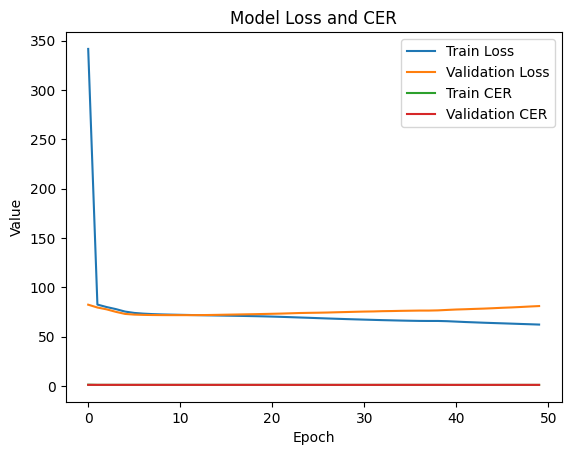

In [123]:
# Cell 11: Define MobileNet + CTC Model
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, LSTM, Bidirectional, Input, Layer

# Custom CTCLayer class
class CTCLayer(Layer):
    def __init__(self, name=None, **kwargs):
        super().__init__(name=name, **kwargs)
        self.loss_fn = tf.keras.backend.ctc_batch_cost

    def call(self, y_true, y_pred, input_length, label_length):
        loss = self.loss_fn(y_true, y_pred, input_length, label_length)
        self.add_loss(loss)
        return y_pred

# Define inputs
image_input = Input(shape=(32, 128, 1), name='image_input')
input_length = Input(shape=(1,), name='input_length')
label_length = Input(shape=(1,), name='label_length')
y_true = Input(shape=(180,), name='labels')  # Padded labels

# Model architecture
x = Conv2D(32, (3, 3), activation='relu')(image_input)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = tf.keras.layers.Reshape((-1, 64))(x)
x = Bidirectional(LSTM(128, return_sequences=True))(x)
x = Dense(len(chars) + 1, activation='softmax', name='dense')(x)  # 38 chars + 1 blank = 39
output = CTCLayer(name='ctc_loss')(y_true, x, input_length, label_length)

# Define model
model = Model(
    inputs=[image_input, input_length, label_length, y_true],
    outputs=[output]
)

# Compile with dummy loss (CTC loss is handled by CTCLayer)
model.compile(optimizer='adam', metrics=['accuracy'])  # Change this to include accuracy as a metric
model.summary()

# Cell 12: Train Model (Full)
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Custom CER metric
# Custom CER metric
# Custom CER metric
def cer_metric(y_true, y_pred):
    # CTC decode predictions
    decoded_preds = tf.keras.backend.ctc_decode(y_pred, input_length=tf.ones(tf.shape(y_pred)[0]) * y_pred.shape[1])[0][0]
    
    # Convert decoded predictions to SparseTensor, excluding -1 (padding)
    pred_indices = tf.where(decoded_preds != -1)
    pred_values = tf.gather_nd(decoded_preds, pred_indices)
    pred_dense_shape = tf.cast(tf.shape(decoded_preds), tf.int64)
    decoded_preds_sparse = tf.SparseTensor(pred_indices, pred_values, pred_dense_shape)
    
    # Convert y_true to SparseTensor, assuming single-character labels
    true_indices = tf.stack([tf.range(tf.shape(y_true)[0], dtype=tf.int64), tf.zeros(tf.shape(y_true)[0], dtype=tf.int64)], axis=1)
    true_values = tf.cast(y_true[:, 0], tf.int32)  # Take first column (single character)
    true_dense_shape = tf.cast(tf.shape(y_true), tf.int64)
    y_true_sparse = tf.SparseTensor(true_indices, true_values, true_dense_shape)
    
    # Ensure both tensors are of the same dtype (int32)
    pred_values = tf.cast(pred_values, tf.int32)  # Cast to int32 to match y_true_sparse
    decoded_preds_sparse = tf.SparseTensor(pred_indices, pred_values, pred_dense_shape)  # Recreate SparseTensor
    
    # Compute edit distance (ensure both tensors are int32)
    edit_distances = tf.edit_distance(decoded_preds_sparse, y_true_sparse, normalize=True)
    
    return tf.reduce_mean(edit_distances)


# Use all available samples
num_samples = len(images)
subset_images = images[:num_samples]
subset_labels = encoded_labels[:num_samples]

# Convert to NumPy arrays if tensors
subset_images = np.array(subset_images) if isinstance(subset_images, tf.Tensor) else subset_images
subset_labels = np.array(subset_labels) if isinstance(subset_labels, tf.Tensor) else subset_labels

# Pad labels
max_label_len = 180
padded_labels = np.zeros((num_samples, max_label_len), dtype=np.float32)
padded_labels[:, :subset_labels.shape[1]] = subset_labels

input_length = np.ones((num_samples, 1), dtype=np.float32) * (128 // 4)  # 32
label_length = np.ones((num_samples, 1), dtype=np.float32)  # Single token

# Train/validation split
train_images, val_images, train_labels, val_labels, train_input_length, val_input_length, train_label_length, val_label_length = train_test_split(
    subset_images, padded_labels, input_length, label_length, test_size=0.2, random_state=42
)

print(f"Training on {len(train_images)} samples, validating on {len(val_images)} samples")
print(f"Train images shape: {train_images.shape}")
print(f"Train labels shape: {train_labels.shape}")
print(f"Val images shape: {val_images.shape}")
print(f"Val labels shape: {val_labels.shape}")

# Create TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices(( 
    {
        'image_input': train_images,
        'input_length': train_input_length,
        'label_length': train_label_length,
        'labels': train_labels
    },
    train_labels
))
train_dataset = train_dataset.batch(16).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices(( 
    {
        'image_input': val_images,
        'input_length': val_input_length,
        'label_length': val_label_length,
        'labels': val_labels
    },
    val_labels
))
val_dataset = val_dataset.batch(16).prefetch(tf.data.AUTOTUNE)

# Recompile model with CER metric
model.compile(optimizer='adam', metrics=[cer_metric])

# Train model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    verbose=1
)
print("Full training complete.")

# Plot training history
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.plot(history.history['cer_metric'], label='Train CER')
plt.plot(history.history['val_cer_metric'], label='Validation CER')
plt.title('Model Loss and CER')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.show()


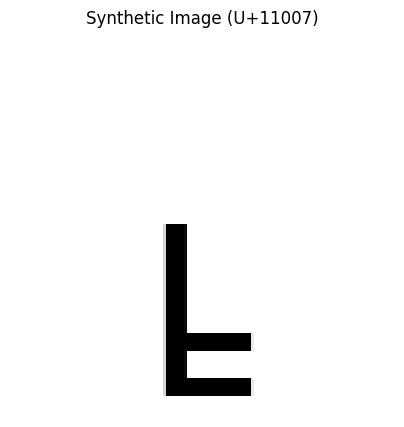

Pixel values: [  0  11 215 235 255]
Tesseract predicted (PSM 6): ட
Tesseract predicted (no lang, PSM 6): L


ValueError: cannot reshape array of size 16384 into shape (1,32,128,1)

In [124]:
# Cell 7: Test OCR on Synthetic Image
import cv2
import pytesseract
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

def decode_predictions(pred, chars):
    # CTC decode to remove blanks and duplicates
    decoded = tf.keras.backend.ctc_decode(pred, input_length=np.ones(pred.shape[0]) * pred.shape[1])[0][0]
    # Convert indices to characters
    output = []
    for seq in decoded:
        text = ''.join([chars[int(i)] for i in seq if i != -1])
        output.append(text)
    return output

synthetic_path = r'Brahmi\brahmi_synthetic_simple\images\U+1100A_0.png'
img = cv2.imread(synthetic_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    print(f"Failed to load: {synthetic_path}")
else:
    # Display image
    plt.figure(figsize=(5, 5))
    plt.title('Synthetic Image (U+11007)')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()
    
    unique_pixels = np.unique(img)
    print(f"Pixel values: {unique_pixels}")
    
    # Tesseract predictions
    text = pytesseract.image_to_string(img, lang='tam', config='--psm 6')
    print(f"Tesseract predicted (PSM 6): {text.strip()}")
    
    text = pytesseract.image_to_string(img, config='--psm 6')
    print(f"Tesseract predicted (no lang, PSM 6): {text.strip()}")
    
    # MobileNet prediction
    img = img / 255.0  # Normalize
    img = img.reshape(1, 32, 128, 1)  # Add batch dimension
    input_length = np.ones((1, 1), dtype=np.float32) * (128 // 4)  # 32
    label_length = np.ones((1, 1), dtype=np.float32)  # Dummy
    dummy_labels = np.zeros((1, 180), dtype=np.float32)  # Dummy
    pred = model.predict({
        'image_input': img,
        'input_length': input_length,
        'label_length': label_length,
        'labels': dummy_labels
    })
    predicted_text = decode_predictions(pred, chars)[0]
    print(f"MobileNet predicted: {predicted_text} (Unicode: {chr(int(predicted_text, 16)) if predicted_text else 'None'})")